**Датасет:** https://archive.ics.uci.edu/dataset/850/raisin

# Лабораторная работа №2. Классификация и многослойный перцептрон
### Отчет по практическому заданию курса «Машинное обучение»

### 1) Введение. Цели и задачи работы

- **Цель работы:** изучить методы классификации из Scikit-Learn и многослойный перцептрон на TensorFlow, сравнить accuracy, precision, recall, F1 и AUC-ROC, проследить влияние гиперпараметров и ход обучения в TensorBoard.
- **Постановка задачи:**
  1. Загрузить морфологические признаки изюма и провести разведочный анализ.
  2. Проверить пропуски и повторы, разделить выборку 80/20 со стратификацией, зафиксировать seed.
  3. Обучить GaussianNB, MultinomialNB, ComplementNB, BernoulliNB, дерево решений, LDA, SVM и kNN.
  4. Подобрать гиперпараметры по кросс-валидации и показать, как они меняют F1.
  5. Обучить многослойный перцептрон на TensorFlow, меняя эпохи, батч, глубину, число нейронов и активацию. Записать логи TensorBoard.
  6. Свести метрики в таблицу, построить ROC и столбчатые диаграммы, выбрать подход для этого датасета.
- **Датасет:** Raisin, UCI. Семь измерений зерна двух сортов, Кечимен и Бесни, снятых машинным зрением. Положительный класс в метриках — Бесни.

### 2) Выбор и подготовка датасета

Набор подготовили И. Чинар, М. Кёклю и Ш. Ташделен: 900 зёрен, по 450 сортов Кечимен и Бесни. Семь признаков сняты с фотографии зерна.

Площадь, длины большой и малой осей, площадь выпуклой оболочки и периметр записаны в пикселях. Эксцентриситет — вытянутость эквивалентного эллипса. Заполненность — доля площади зерна внутри описывающего прямоугольника. Эти две величины безразмерные и лежат между 0 и 1. Из-за пиксельных масштабов расстояние и линейные модели без стандартизации смотрят почти только на площадь.

В файле сорт записан словом. Дальше он переведён в числа: Кечимен — 0, Бесни — 1. Бесни — положительный класс precision, recall и F1. В матрице ошибок строки — истинный сорт, столбцы — прогноз, порядок один и тот же: сначала Кечимен, затем Бесни. Правая нижняя клетка — верно найденные зёрна Бесни.

Сорта равны по числу, поэтому accuracy и F1 описывают одно и то же качество. Зёрна пересекаются по размеру, и точность на отложенной выборке ниже единицы.

In [1]:
%matplotlib inline
import os
import warnings

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, make_scorer, confusion_matrix,
)
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB, BernoulliNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["font.size"] = 11
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.autolayout"] = True

SEED = 42
np.random.seed(SEED)

RU = {
    "Area": "Площадь",
    "MajorAxisLength": "Длина большой оси",
    "MinorAxisLength": "Длина малой оси",
    "Eccentricity": "Эксцентриситет",
    "ConvexArea": "Площадь оболочки",
    "Extent": "Заполненность",
    "Perimeter": "Периметр",
    "Class": "Бесни",
}
TARGET = "Бесни"
FEATURES = [name for key, name in RU.items() if key != "Class"]
LABELS = {0: "Кечимен (0)", 1: "Бесни (1)"}

df_raw = pd.read_csv("data/raisin.csv")
df_raw["Class"] = (df_raw["Class"] == "Besni").astype(int)
df_raw = df_raw.rename(columns=RU)

print("=" * 80)
print(f"Размерность: {df_raw.shape[0]} строк, {df_raw.shape[1]} столбцов")
print("=" * 80)
print("\nПервые 5 строк:")
print(df_raw.head().round(2).to_string(index=False))
print("\nТипы:")
print(df_raw.dtypes.to_string())
print("\nПропуски:")
print(df_raw.isnull().sum().to_string())
print(f"\nДубликатов: {int(df_raw.duplicated().sum())}")
balance = df_raw[TARGET].value_counts().rename(LABELS)
share = (df_raw[TARGET].value_counts(normalize=True) * 100).rename(LABELS)
print("\nКлассы в исходном файле:")
print(pd.DataFrame({"Число": balance, "Доля, %": share.round(2)}).to_string())

Размерность: 900 строк, 8 столбцов

Первые 5 строк:
 Площадь  Длина большой оси  Длина малой оси  Эксцентриситет  Площадь оболочки  Заполненность  Периметр  Бесни
   87524             442.25           253.29            0.82             90546           0.76   1184.04      0
   75166             406.69           243.03            0.80             78789           0.68   1121.79      0
   90856             442.27           266.33            0.80             93717           0.64   1208.58      0
   45928             286.54           208.76            0.68             47336           0.70    844.16      0
   79408             352.19           290.83            0.56             81463           0.79   1073.25      0

Типы:
Площадь                int64
Длина большой оси    float64
Длина малой оси      float64
Эксцентриситет       float64
Площадь оболочки       int64
Заполненность        float64
Периметр             float64
Бесни                  int64

Пропуски:
Площадь              0
Длина бол

### Пояснение к первичному анализу

- В файле 900 зёрен и 8 столбцов. Пропусков нет, полных повторов нет.
- Сорта строго поровну: 450 и 450. Стратификация сохраняет эту долю.
- Площадь и периметр имеют другой масштаб, чем эксцентриситет и заполненность. Перед методами, которые смотрят на расстояние или на линейную комбинацию, нужна стандартизация.
- Признаки неотрицательные. Для MultinomialNB и ComplementNB это подходит по знаку, но не по смыслу: модель ждёт частоты, а здесь пиксельные размеры.

После удаления дубликатов: 900 строк
                     Среднее  Станд. откл.    Медиана    Минимум    Максимум  Асимметрия
Площадь            87804.128     39002.111  78902.000  25387.000  235047.000       1.175
Длина большой оси    430.930       116.035    407.804    225.630     997.292       0.990
Длина малой оси      254.488        49.989    247.848    143.711     492.275       0.800
Эксцентриситет         0.782         0.090      0.799      0.349       0.962      -1.328
Площадь оболочки   91186.090     40769.290  81651.000  26139.000  278217.000       1.243
Заполненность          0.700         0.053      0.707      0.380       0.835      -1.152
Периметр            1165.907       273.764   1119.509    619.074    2697.753       1.018
Бесни                  0.500         0.500      0.500      0.000       1.000       0.000

Классы после очистки:
             Число  Доля, %
Бесни                      
Кечимен (0)    450     50.0
Бесни (1)      450     50.0

Средние по сортам:
       

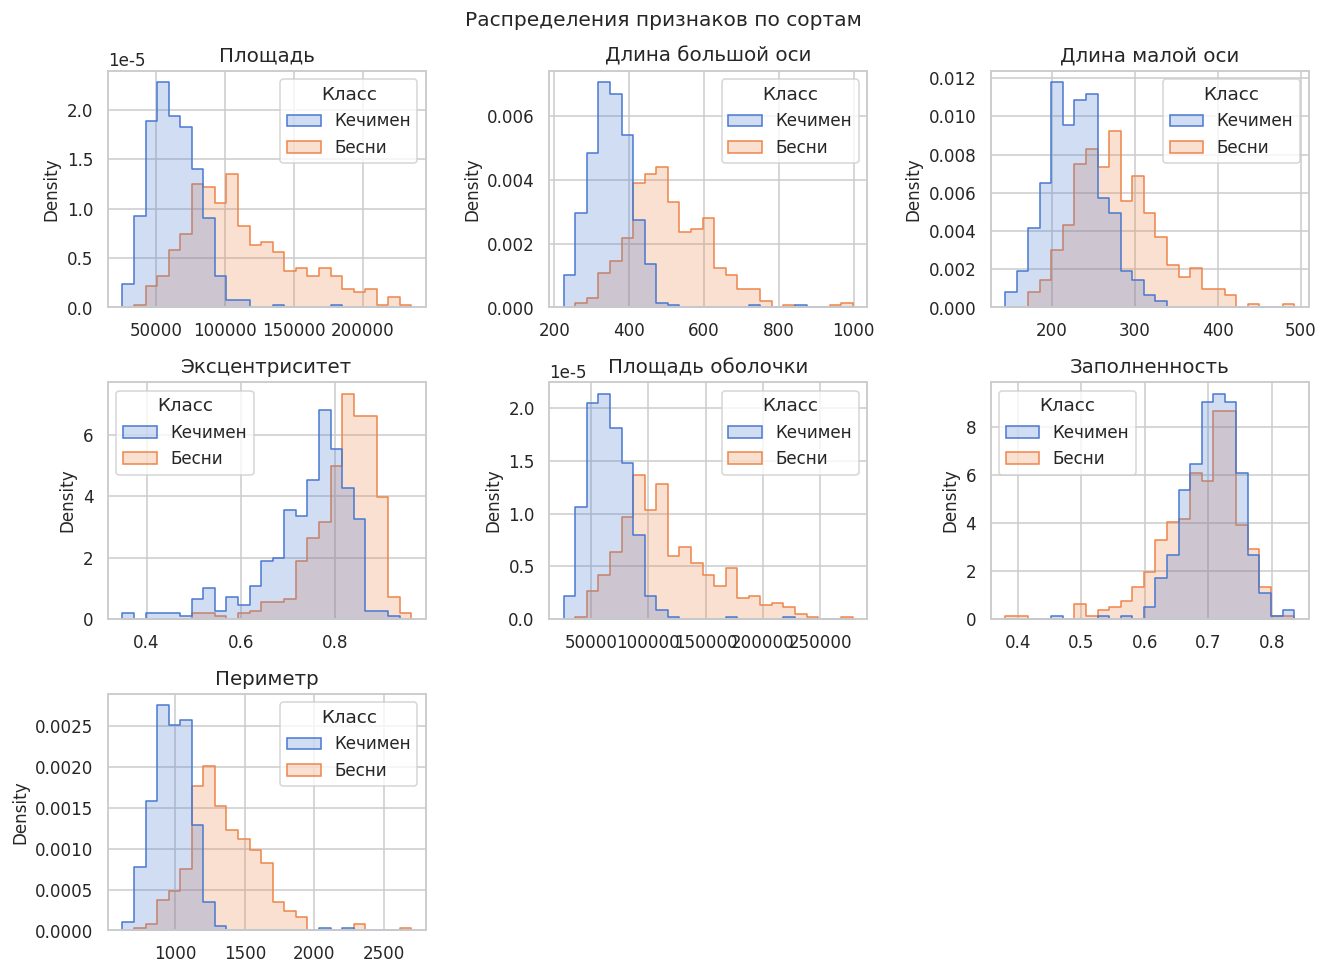

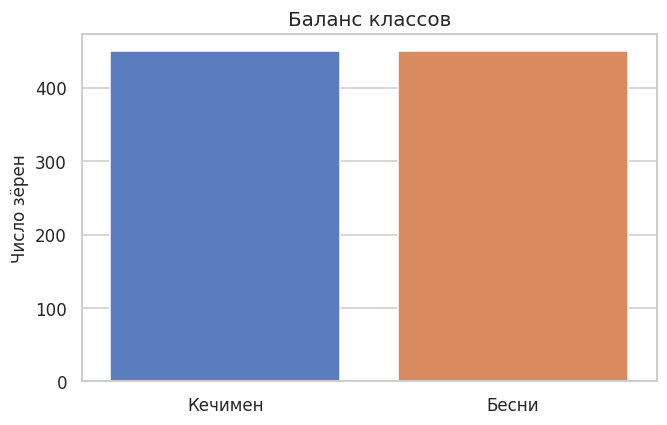

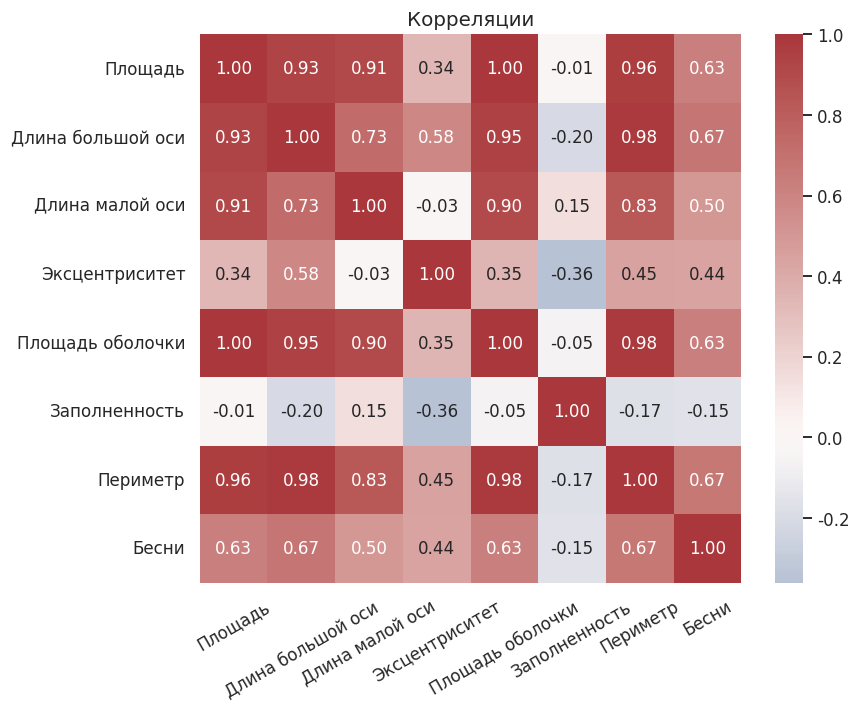

In [2]:
df = df_raw.drop_duplicates().reset_index(drop=True)
stat = df.describe().T
summary = pd.DataFrame({
    "Среднее": stat["mean"],
    "Станд. откл.": stat["std"],
    "Медиана": stat["50%"],
    "Минимум": stat["min"],
    "Максимум": stat["max"],
    "Асимметрия": df.skew(numeric_only=True),
}).round(3)
print(f"После удаления дубликатов: {len(df)} строк")
print(summary.to_string())
balance = df[TARGET].value_counts().rename(LABELS)
share = (df[TARGET].value_counts(normalize=True) * 100).rename(LABELS)
print("\nКлассы после очистки:")
print(pd.DataFrame({"Число": balance, "Доля, %": share.round(2)}).to_string())
print("\nСредние по сортам:")
print(df.groupby(TARGET)[FEATURES].mean().rename(index={0: "Кечимен", 1: "Бесни"}).round(2).to_string())

plot_df = df.copy()
plot_df["Класс"] = plot_df[TARGET].map({0: "Кечимен", 1: "Бесни"})
fig, axes = plt.subplots(3, 3, figsize=(12.2, 9.0))
for ax, col in zip(axes.ravel(), FEATURES):
    sns.histplot(data=plot_df, x=col, hue="Класс", bins=25, element="step", stat="density", common_norm=False, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
for ax in axes.ravel()[len(FEATURES):]:
    ax.axis("off")
fig.suptitle("Распределения признаков по сортам")
plt.show()

fig, ax = plt.subplots(figsize=(6.2, 4.0))
sns.countplot(data=plot_df, x="Класс", hue="Класс", legend=False, ax=ax, order=["Кечимен", "Бесни"])
ax.set_xlabel("")
ax.set_ylabel("Число зёрен")
ax.set_title("Баланс классов")
plt.show()

corr = df.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(8.2, 6.6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax)
ax.set_title("Корреляции")
ax.tick_params(axis="x", rotation=30)
plt.show()

### Пояснение к графикам

Бесни в среднем крупнее: площадь, оси и периметр сдвинуты вправо, но распределения двух сортов накрывают друг друга. Одного порога по площади недостаточно, чтобы разложить все зёрна без ошибок.

Площадь и площадь оболочки коррелируют почти на единицу, периметр повторяет длину большой оси. Это один и тот же сигнал размера, записанный несколько раз. Эксцентриситет и заполненность слабее связаны с площадью и несут форму. Все семь признаков остаются: дерево и регуляризация сами снижают вес повторов, а таблица корреляций показывает, почему часть моделей не выигрывает от лишних столбцов.

### 3) Разбиение выборки

80% зёрен идут в обучение, 20% остаются отложенной выборкой. `random_state=42`, разбиение стратифицированное. После разбиения печатается число строк, у которых все признаки совпали с обучающей частью: такие совпадения означали бы утечку копий.

Масштаб для расстояний, LDA, SVM и сети считается внутри пайплайна или на обучающей части. MultinomialNB и ComplementNB получают признаки после сдвига минимума обучающей части в ноль. На этих данных сдвиг почти ничего не меняет, потому что размеры и так неотрицательные. BernoulliNB видит только факт «значение выше квантиля обучающей части». Квантиль подбирается на кросс-валидации; значение 0,5 совпадает с медианой.

In [3]:
class ShiftToNonNegative(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        self.minimum_ = np.min(np.asarray(X, dtype=float), axis=0)
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float) - self.minimum_, 0, None)


class QuantileBinarizer(BaseEstimator, TransformerMixin):
    def __init__(self, quantile=0.5):
        self.quantile = quantile

    def fit(self, X, y=None):
        values = np.asarray(X, dtype=float)
        if self.quantile == 0.5:
            self.threshold_ = np.median(values, axis=0)
        else:
            self.threshold_ = np.quantile(values, self.quantile, axis=0)
        return self

    def transform(self, X):
        return (np.asarray(X, dtype=float) > self.threshold_).astype(float)


X = df[FEATURES].copy()
y = df[TARGET].copy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
f1_scorer = make_scorer(f1_score, zero_division=0)

print(f"Обучение: {len(y_train)}, тест: {len(y_test)}, признаков: {X.shape[1]}")
print(f"Доля Бесни, train / test: {y_train.mean():.3f} / {y_test.mean():.3f}")
train_keys = set(map(tuple, np.round(X_train.to_numpy(dtype=float), 5)))
overlap = sum(tuple(row) in train_keys for row in np.round(X_test.to_numpy(dtype=float), 5))
print(f"Совпавших по признакам строк train/test: {overlap}")
print("Признаки:")
for name in FEATURES:
    print(f"  - {name}")

Обучение: 720, тест: 180, признаков: 7
Доля Бесни, train / test: 0.500 / 0.500
Совпавших по признакам строк train/test: 0
Признаки:
  - Площадь
  - Длина большой оси
  - Длина малой оси
  - Эксцентриситет
  - Площадь оболочки
  - Заполненность
  - Периметр


### Пояснение к разбиению

Доли Бесни в обучении и в тесте совпадают. Совпавших строк между частями нет, одна и та же зерновка не попадает в обе выборки. Основной критерий подбора — F1 класса «Бесни». AUC-ROC сравнивает ранжирование без порога. Seed равен 42.

### 4) Методы классификации

**Наивный Байес.** Апостериорная вероятность класса при условной независимости признаков.

- `GaussianNB` считает признак нормальным внутри класса. На вход идёт стандартизированная матрица. Параметр `var_smoothing` стабилизирует дисперсию.
- `MultinomialNB` работает с неотрицательными величинами. Здесь это размеры зерна, не частоты. Параметр `alpha` — сглаживание. Сетка идёт от 1 до 100000: при площадях в десятки тысяч пикселей малое `alpha` не меняет вероятности.
- `ComplementNB` оценивает дополнение класса на тех же неотрицательных признаках и с той же сеткой `alpha`.
- `BernoulliNB` использует бинарную версию признаков. Порог — квантиль обучающей части фолда. При равных долях классов `alpha` не меняет предсказанный сорт, поэтому варьируется квантиль.

**Дерево решений.** Пороги по одному признаку. Варьируются глубина, размер листа и вес классов.

**LDA.** Линейная проекция при общей ковариации. `shrinkage` подтягивает ковариацию к диагональной. Это уместно: площадь и оболочка почти коллинеарны.

**SVM.** Зазор между классами. Сетка сравнивает линейное ядро и RBF, штраф `C`, ширину `gamma` и вес классов. Для ROC включена калибровка вероятностей.

**kNN.** Класс большинства среди `k` соседей в стандартизированном пространстве. Варьируются `k`, веса и метрика.

### 5) Настройка гиперпараметров

Сетка ищется 5-фолдовой стратифицированной кросс-валидацией на обучении. Критерий — F1 класса «Бесни». Тест в подборе не участвует.

GaussianNB: CV F1 = 0.801 ± 0.040
  параметры: {'clf__var_smoothing': np.float64(1e-11)}
MultinomialNB: CV F1 = 0.787 ± 0.056
  параметры: {'clf__alpha': 1000}


ComplementNB: CV F1 = 0.787 ± 0.056
  параметры: {'clf__alpha': 1000}
BernoulliNB: CV F1 = 0.845 ± 0.037
  параметры: {'bin__quantile': 0.5}


Дерево: CV F1 = 0.828 ± 0.037
  параметры: {'clf__class_weight': None, 'clf__max_depth': 2, 'clf__min_samples_leaf': 1}
LDA: CV F1 = 0.837 ± 0.042
  параметры: {'clf__shrinkage': 0.3}


SVM: CV F1 = 0.850 ± 0.039
  параметры: {'clf__C': 1, 'clf__class_weight': None, 'clf__kernel': 'linear'}


kNN: CV F1 = 0.846 ± 0.037
  параметры: {'clf__metric': 'manhattan', 'clf__n_neighbors': 41, 'clf__weights': 'distance'}


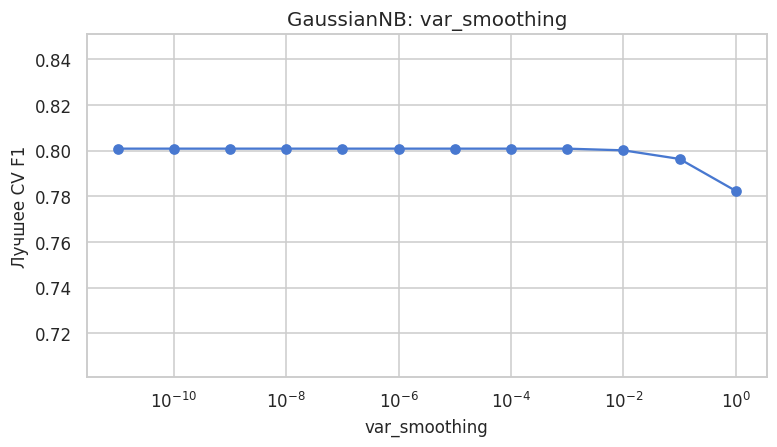

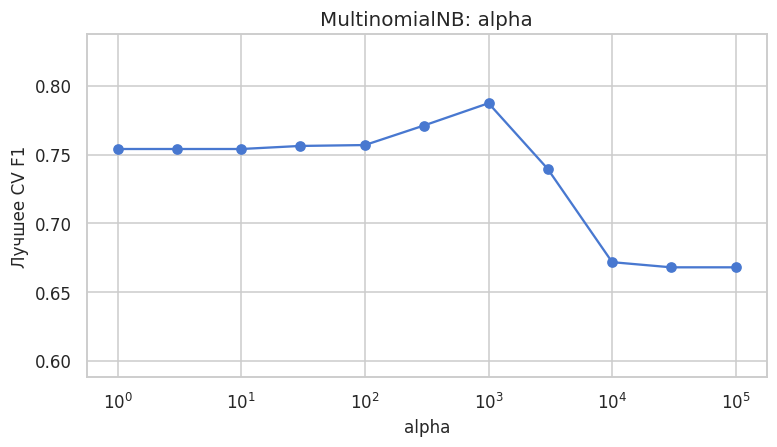

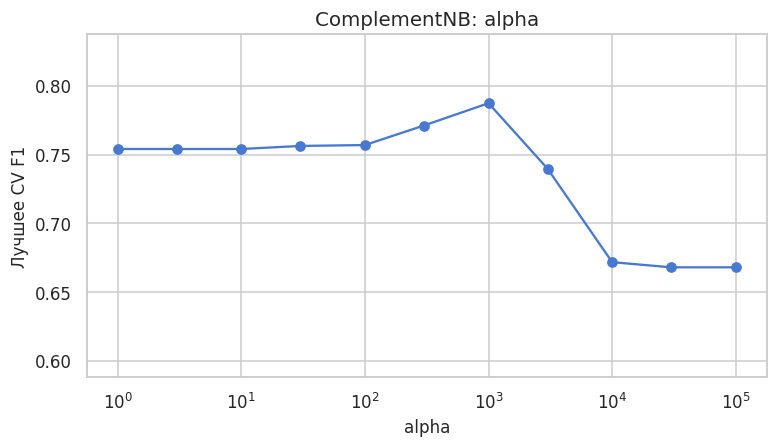

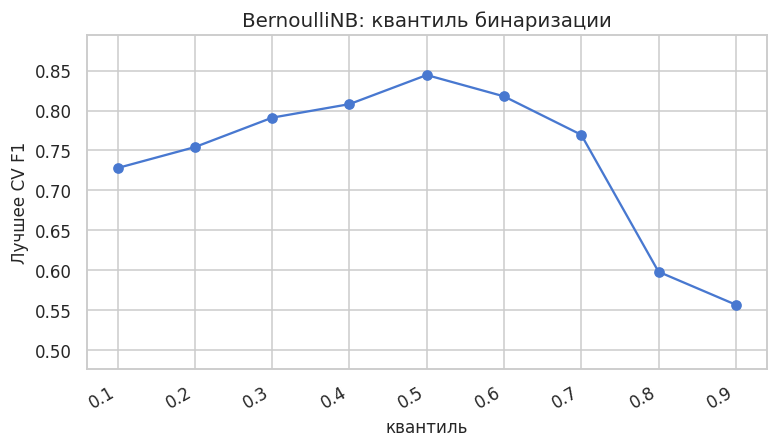

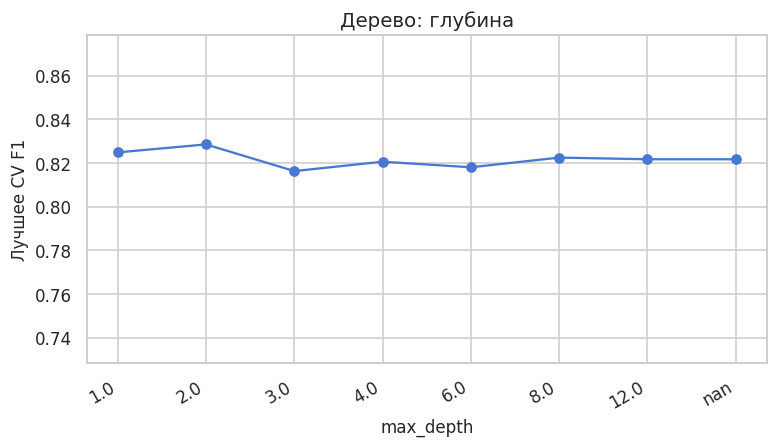

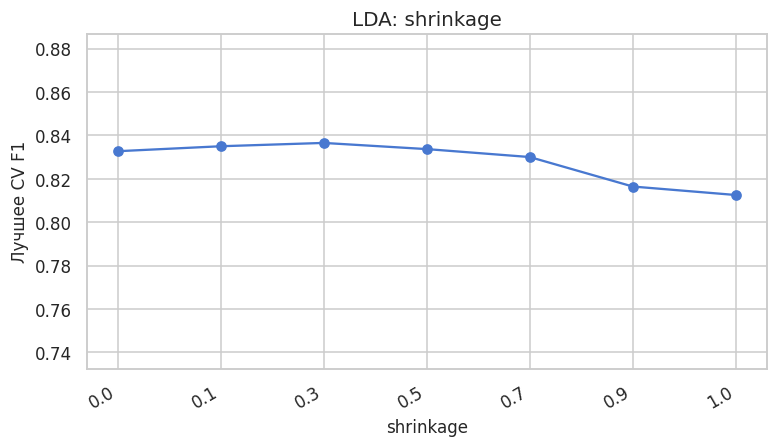

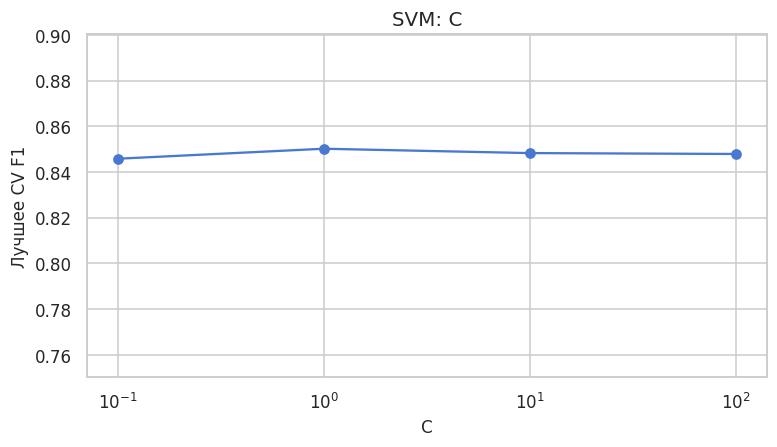

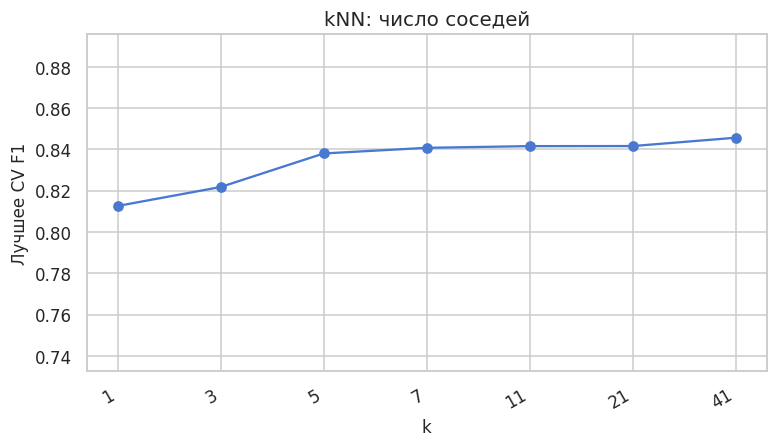

In [4]:
def fit_grid(name, estimator, param_grid):
    search = GridSearchCV(estimator, param_grid, scoring=f1_scorer, cv=cv, n_jobs=1, refit=True)
    search.fit(X_train, y_train)
    std = float(search.cv_results_["std_test_score"][search.best_index_])
    print(f"{name}: CV F1 = {search.best_score_:.3f} ± {std:.3f}")
    print(f"  параметры: {search.best_params_}")
    return search


def plot_param_curve(search, param, title, xlabel, logx=False):
    frame = pd.DataFrame(search.cv_results_)
    best = frame.groupby(f"param_{param}", dropna=False)["mean_test_score"].max()
    fig, ax = plt.subplots(figsize=(7.2, 4.2))
    if logx:
        ax.plot(best.index.astype(float), best.values, marker="o")
        ax.set_xscale("log")
    else:
        labels = ["нет" if value is None else str(value) for value in best.index]
        ax.plot(range(len(best)), best.values, marker="o")
        ax.set_xticks(range(len(best)))
        ax.set_xticklabels(labels, rotation=30, ha="right")
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Лучшее CV F1")
    lower = max(0.0, float(best.min()) - 0.08)
    upper = min(1.02, float(best.max()) + 0.05)
    if upper - lower < 0.15:
        lower = max(0.0, upper - 0.15)
    ax.set_ylim(lower, upper)
    plt.show()


grids = {}
grids["GaussianNB"] = fit_grid(
    "GaussianNB",
    Pipeline([("scaler", StandardScaler()), ("clf", GaussianNB())]),
    {"clf__var_smoothing": np.logspace(-11, 0, 12)},
)
grids["MultinomialNB"] = fit_grid(
    "MultinomialNB",
    Pipeline([("shift", ShiftToNonNegative()), ("clf", MultinomialNB())]),
    {"clf__alpha": [1, 3, 10, 30, 100, 300, 1000, 3000, 10000, 30000, 100000]},
)
grids["ComplementNB"] = fit_grid(
    "ComplementNB",
    Pipeline([("shift", ShiftToNonNegative()), ("clf", ComplementNB())]),
    {"clf__alpha": [1, 3, 10, 30, 100, 300, 1000, 3000, 10000, 30000, 100000]},
)
grids["BernoulliNB"] = fit_grid(
    "BernoulliNB",
    Pipeline([("bin", QuantileBinarizer()), ("clf", BernoulliNB())]),
    {"bin__quantile": [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]},
)
grids["Дерево"] = fit_grid(
    "Дерево",
    Pipeline([("scaler", StandardScaler()), ("clf", DecisionTreeClassifier(random_state=SEED))]),
    {
        "clf__max_depth": [1, 2, 3, 4, 6, 8, 12, None],
        "clf__min_samples_leaf": [1, 2, 4, 8],
        "clf__class_weight": [None, "balanced"],
    },
)
grids["LDA"] = fit_grid(
    "LDA",
    Pipeline([("scaler", StandardScaler()), ("clf", LinearDiscriminantAnalysis(solver="lsqr"))]),
    {"clf__shrinkage": [0.0, 0.1, 0.3, 0.5, 0.7, 0.9, 1.0]},
)
grids["SVM"] = fit_grid(
    "SVM",
    Pipeline([("scaler", StandardScaler()), ("clf", SVC(probability=True, random_state=SEED))]),
    [
        {"clf__kernel": ["linear"], "clf__C": [0.1, 1, 10, 100], "clf__class_weight": [None, "balanced"]},
        {
            "clf__kernel": ["rbf"],
            "clf__C": [0.1, 1, 10, 100],
            "clf__gamma": ["scale", 0.1, 1],
            "clf__class_weight": [None, "balanced"],
        },
    ],
)
grids["kNN"] = fit_grid(
    "kNN",
    Pipeline([("scaler", StandardScaler()), ("clf", KNeighborsClassifier())]),
    {
        "clf__n_neighbors": [1, 3, 5, 7, 11, 21, 41],
        "clf__weights": ["uniform", "distance"],
        "clf__metric": ["euclidean", "manhattan"],
    },
)

plot_param_curve(grids["GaussianNB"], "clf__var_smoothing", "GaussianNB: var_smoothing", "var_smoothing", logx=True)
plot_param_curve(grids["MultinomialNB"], "clf__alpha", "MultinomialNB: alpha", "alpha", logx=True)
plot_param_curve(grids["ComplementNB"], "clf__alpha", "ComplementNB: alpha", "alpha", logx=True)
plot_param_curve(grids["BernoulliNB"], "bin__quantile", "BernoulliNB: квантиль бинаризации", "квантиль")
plot_param_curve(grids["Дерево"], "clf__max_depth", "Дерево: глубина", "max_depth")
plot_param_curve(grids["LDA"], "clf__shrinkage", "LDA: shrinkage", "shrinkage")
plot_param_curve(grids["SVM"], "clf__C", "SVM: C", "C", logx=True)
plot_param_curve(grids["kNN"], "clf__n_neighbors", "kNN: число соседей", "k")

### Пояснение к подбору параметров

Кривые читаются вместе с лучшими параметрами над графиками. На перекрывающихся сортах F1 не выходит на единицу.

У MultinomialNB и ComplementNB при `alpha` от 1 до 10 линия горизонтальная: такая добавка не видна на площади в десятки тысяч пикселей. Дальше F1 растёт, максимум около `alpha` = 1000, затем сглаживание затирает размеры и кривая падает. У BernoulliNB при равных долях сортов `alpha` не переворачивает решение, поэтому на графике квантиль порога: F1 растёт до 0,5 и после медианы снижается.

Глубина дерева и число соседей тоже сдвигают F1. Слишком глубокое дерево и слишком малый `k` уступают более устойчивому варианту.


### Метрики на отложенной выборке

Precision, recall и F1 считаются для класса «Бесни». Сначала используется стандартное решающее правило модели. Затем порог, максимизирующий F1, подбирается по внефолдовым вероятностям обучения и применяется к тесту.

СТАНДАРТНОЕ РЕШАЮЩЕЕ ПРАВИЛО
               Accuracy  Precision  Recall     F1  AUC-ROC
Модель                                                    
GaussianNB        0.867      0.971   0.756  0.850    0.945
MultinomialNB     0.833      0.857   0.800  0.828    0.888
ComplementNB      0.833      0.857   0.800  0.828    0.888
BernoulliNB       0.900      0.919   0.878  0.898    0.939
Дерево            0.894      0.918   0.867  0.891    0.921
LDA               0.889      0.961   0.811  0.880    0.957
SVM               0.928      0.953   0.900  0.926    0.959
kNN               0.911      0.962   0.856  0.906    0.955

ПОРОГ ПО F1 НА ОБУЧАЮЩИХ ФОЛДАХ
               Порог  Accuracy  Precision  Recall     F1  AUC-ROC
Модель                                                           
GaussianNB     0.050     0.894      0.918   0.867  0.891    0.945
MultinomialNB  0.700     0.833      0.866   0.789  0.826    0.888
ComplementNB   0.700     0.833      0.866   0.789  0.826    0.888
BernoulliNB    0.4

GaussianNB: TN=88, FP=2, FN=22, TP=68; precision=0.971, recall=0.756


MultinomialNB: TN=78, FP=12, FN=18, TP=72; precision=0.857, recall=0.800


ComplementNB: TN=78, FP=12, FN=18, TP=72; precision=0.857, recall=0.800
BernoulliNB: TN=83, FP=7, FN=11, TP=79; precision=0.919, recall=0.878


Дерево: TN=83, FP=7, FN=12, TP=78; precision=0.918, recall=0.867
LDA: TN=87, FP=3, FN=17, TP=73; precision=0.961, recall=0.811


SVM: TN=86, FP=4, FN=9, TP=81; precision=0.953, recall=0.900
kNN: TN=87, FP=3, FN=13, TP=77; precision=0.963, recall=0.856


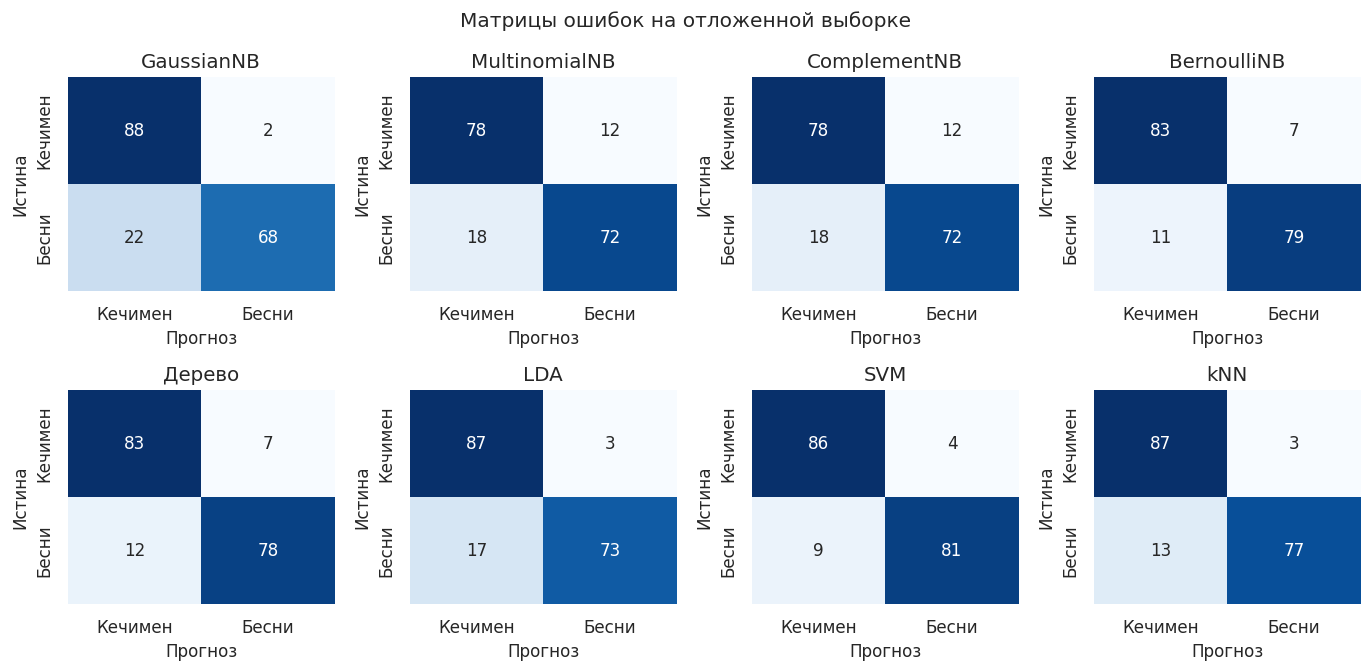

In [5]:
def positive_scores(model, features):
    proba = model.predict_proba(features)
    return proba[:, list(model.classes_).index(1)]


def metric_row(name, y_true, pred, scores):
    return {
        "Модель": name,
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
        "AUC-ROC": roc_auc_score(y_true, scores),
    }


def best_threshold(y_true, scores):
    best_t, best_f = 0.5, -1.0
    for threshold in np.linspace(0.05, 0.95, 37):
        value = f1_score(y_true, (scores >= threshold).astype(int), zero_division=0)
        if value > best_f:
            best_t, best_f = float(threshold), float(value)
    return best_t


rows, tuned_rows, score_bank = [], [], {}
for name, search in grids.items():
    model = search.best_estimator_
    scores = positive_scores(model, X_test)
    score_bank[name] = scores
    rows.append(metric_row(name, y_test, model.predict(X_test), scores))
    oof = cross_val_predict(model, X_train, y_train, cv=cv, method="predict_proba")
    oof_pos = oof[:, list(model.classes_).index(1)]
    threshold = best_threshold(y_train, oof_pos)
    tuned = metric_row(name, y_test, (scores >= threshold).astype(int), scores)
    tuned["Порог"] = threshold
    tuned_rows.append(tuned)

metrics_cls = pd.DataFrame(rows).set_index("Модель")
metrics_tuned = pd.DataFrame(tuned_rows).set_index("Модель")
print("СТАНДАРТНОЕ РЕШАЮЩЕЕ ПРАВИЛО")
print(metrics_cls.round(3).to_string())
print("\nПОРОГ ПО F1 НА ОБУЧАЮЩИХ ФОЛДАХ")
print(metrics_tuned[["Порог", "Accuracy", "Precision", "Recall", "F1", "AUC-ROC"]].round(3).to_string())
print(f"\nЛучший F1: {metrics_cls['F1'].idxmax()} ({metrics_cls['F1'].max():.3f})")
print(f"Лучший AUC: {metrics_cls['AUC-ROC'].idxmax()} ({metrics_cls['AUC-ROC'].max():.3f})")
CLASS_NAMES = ["Кечимен", "Бесни"]
fig, axes = plt.subplots(2, 4, figsize=(12.6, 6.2))
print("МАТРИЦА ОШИБОК НА ТЕСТЕ, ПОРОГ 0.5")
print("Строки — истина, столбцы — прогноз: Кечимен, Бесни")
for ax, (name, search) in zip(axes.ravel(), grids.items()):
    pred = search.best_estimator_.predict(X_test)
    matrix = confusion_matrix(y_test, pred, labels=[0, 1])
    tn, fp, fn, tp = matrix.ravel()
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    sns.heatmap(
        matrix, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
        xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
    )
    ax.set_xlabel("Прогноз")
    ax.set_ylabel("Истина")
    ax.set_title(name)
    print(f"{name}: TN={tn}, FP={fp}, FN={fn}, TP={tp}; precision={precision:.3f}, recall={recall:.3f}")
fig.suptitle("Матрицы ошибок на отложенной выборке")
plt.show()

### Пояснение к качеству классификаторов

Совпавших строк между обучением и тестом нет. На отложенной выборке **90** Кечимен и **90** Бесни. В матрице ошибок строка — истинный сорт, столбец — прогноз, слева направо и сверху вниз: Кечимен, затем Бесни. Для положительного класса Бесни это клетки TN, FP, FN, TP. Precision = TP / (TP + FP), recall = TP / (TP + FN). Пересчёт из матрицы совпадает с таблицей метрик.

У **SVM** матрица такая: Кечимен угадан **86** раз и **4** раза назван Бесни; Бесни пропущен **9** раз и угадан **81**. Отсюда precision **81 / 85 = 0,953**, recall **81 / 90 = 0,900**, accuracy **167 / 180 = 0,928**, F1 **0,926**, AUC **0,959**.

kNN: TN **87**, FP **3**, FN **13**, TP **77**, F1 **0,906**. BernoulliNB: TN **83**, FP **7**, FN **11**, TP **79**, F1 **0,898**. Дерево глубины 2: TN **83**, FP **7**, FN **12**, TP **78**, F1 **0,891**. LDA: TN **87**, FP **3**, FN **17**, TP **73**, F1 **0,880**, AUC **0,957**. GaussianNB: TN **88**, FP **2**, FN **22**, TP **68**, F1 **0,850**: ложных Бесни мало, пропусков много. MultinomialNB и ComplementNB совпали при alpha = 1000: TN **78**, FP **12**, FN **18**, TP **72**. Precision **72 / 84 = 0,857**, recall **72 / 90 = 0,800**, F1 **0,828**.

Подбор порога по обучающим фолдам поднимает F1 GaussianNB до **0,891** и LDA до **0,905**, а у SVM снижает F1 с **0,926** до **0,916**. Лидер не меняется.

### 6) Многослойный перцептрон на TensorFlow

Это многослойный перцептрон: полносвязная сеть прямого распространения, без свёрток и рекуррентных слоёв. На вход идут семь стандартизированных промеров зерна. Скрытые слои — Dense, в финальной модели 32, 16 и 8 нейронов с сигмоидой. Выход — один нейрон с сигмоидой, его значение есть вероятность сорта Бесни. Функция потерь — бинарная кросс-энтропия, оптимизатор — Adam со скоростью 0,001.

Обучение перцептрона делится ещё раз 80/20 на подвыборку градиента и валидацию. Тест закрыт до финальной оценки. Сравниваются веса классов, число эпох, размер батча, архитектура и функция активации. Финальный перцептрон собирается из лучшего значения каждого опыта по валидационному F1.

Логи лежат в `logs/nn`. Запуск из папки `lab2`:

```text
tensorboard --logdir logs/nn
```

Веса классов: {0: 1.0, 1: 1.0}
Перцептрон: обучение 576, валидация 144, тест 180


Режим весов для остальных опытов: без весов


        Опыт          Значение  Val Accuracy  Val Precision  Val Recall  Val F1  Val AUC
веса классов         без весов         0.861          0.919       0.792   0.851    0.936
веса классов          balanced         0.861          0.919       0.792   0.851    0.936
       эпохи                15         0.868          0.921       0.806   0.859    0.935
       эпохи                40         0.861          0.919       0.792   0.851    0.936
       эпохи                80         0.868          0.921       0.806   0.859    0.933
        батч                 8         0.868          0.921       0.806   0.859    0.935
        батч                16         0.861          0.919       0.792   0.851    0.936
        батч                32         0.868          0.921       0.806   0.859    0.938
        батч                64         0.868          0.921       0.806   0.859    0.936
 архитектура                 8         0.875          0.922       0.819   0.868    0.940
 архитектура         

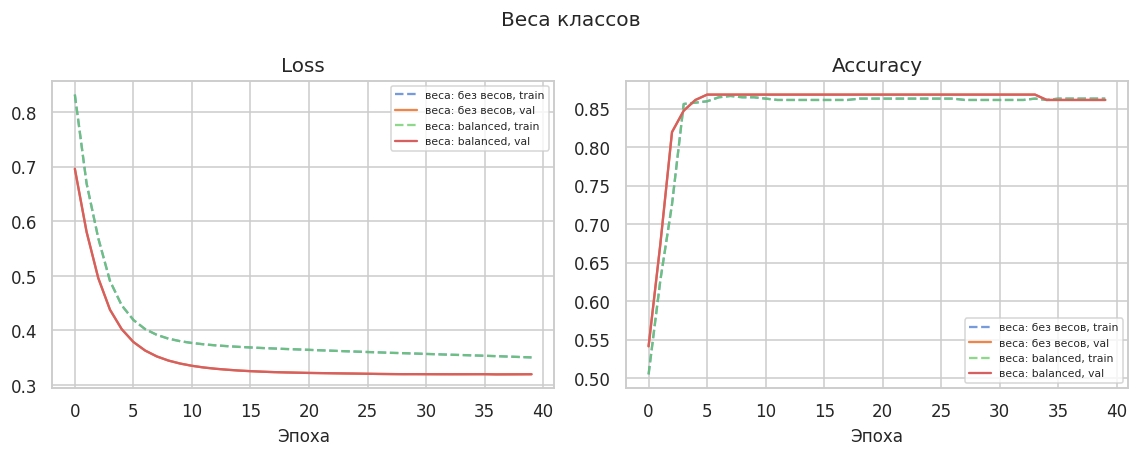

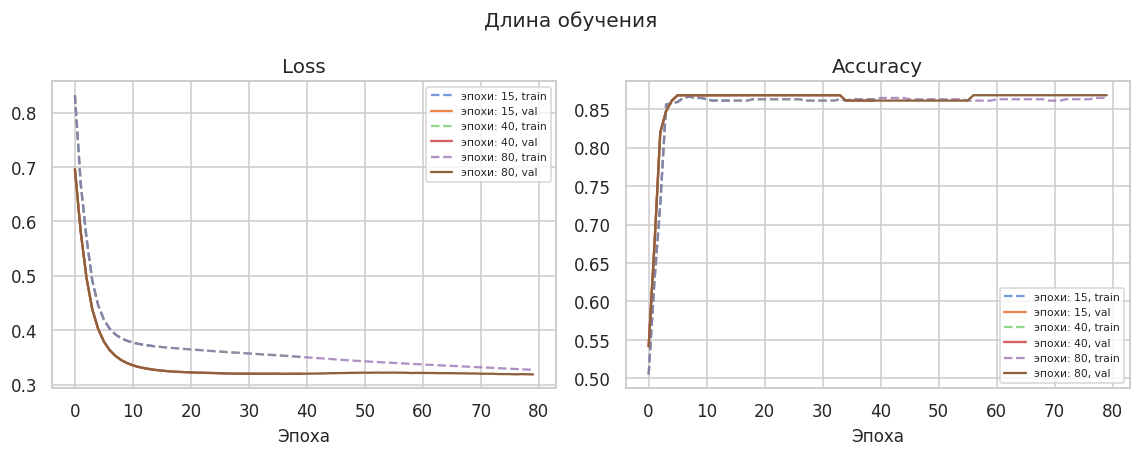

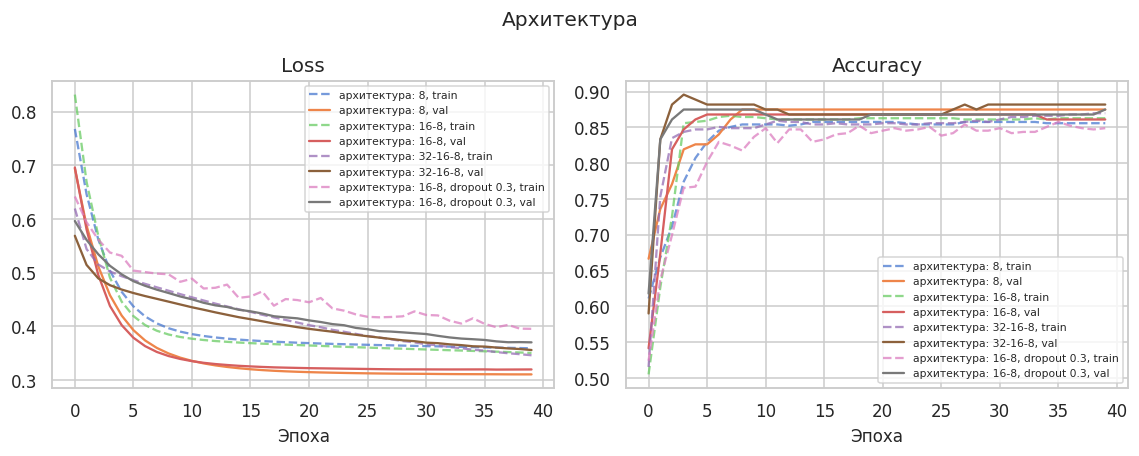

Финал: веса без весов, эпохи 15, батч 32, слои (32, 16, 8), dropout 0.0, активация sigmoid


Тест, порог 0.5
Модель       Перцептрон
Accuracy       0.788889
Precision      0.713115
Recall         0.966667
F1             0.820755
AUC-ROC        0.954691
Тест, порог валидации 0.525
Модель       Перцептрон
Accuracy       0.911111
Precision      0.930233
Recall         0.888889
F1             0.909091
AUC-ROC        0.954691
Порог             0.525


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,789 (10.90 KB)

 Trainable params: 929 (3.63 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,860 (7.27 KB)

Файлов TensorBoard: 136
Матрица ошибок перцептрона, порог 0.5
                Прогноз Кечимен  Прогноз Бесни
Истина Кечимен               55             35
Истина Бесни                  3             87
Матрица ошибок перцептрона, порог 0.525
                Прогноз Кечимен  Прогноз Бесни
Истина Кечимен               84              6
Истина Бесни                 10             80


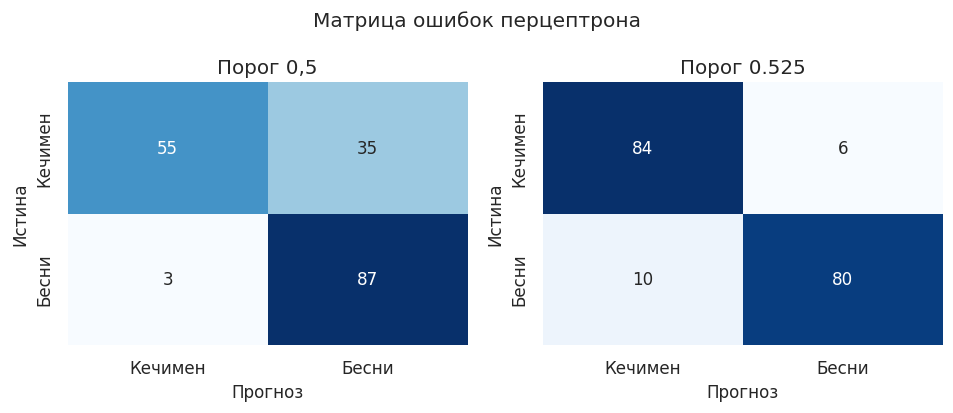

In [6]:
import tensorflow as tf

tf.get_logger().setLevel("ERROR")
tf.keras.utils.set_random_seed(SEED)

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.20, random_state=SEED, stratify=y_train
)
nn_scaler = StandardScaler()
X_fit_s = nn_scaler.fit_transform(X_fit)
X_val_s = nn_scaler.transform(X_val)
X_test_s = nn_scaler.transform(X_test)
y_fit_np = y_fit.to_numpy()
y_val_np = y_val.to_numpy()
y_test_np = y_test.to_numpy()
n_pos = max(int((y_fit_np == 1).sum()), 1)
n_neg = max(int((y_fit_np == 0).sum()), 1)
weight_balanced = {0: len(y_fit_np) / (2 * n_neg), 1: len(y_fit_np) / (2 * n_pos)}
print("Веса классов:", {key: round(value, 3) for key, value in weight_balanced.items()})
print(f"Перцептрон: обучение {len(y_fit_np)}, валидация {len(y_val_np)}, тест {len(y_test_np)}")


def build_nn(layers, activation, dropout, lr):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    model = tf.keras.Sequential()
    model.add(tf.keras.layers.Input(shape=(X_fit_s.shape[1],)))
    for index, units in enumerate(layers):
        model.add(tf.keras.layers.Dense(units, activation=activation))
        if dropout and index < len(layers) - 1:
            model.add(tf.keras.layers.Dropout(dropout))
    model.add(tf.keras.layers.Dense(1, activation="sigmoid"))
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss="binary_crossentropy",
        metrics=["accuracy"],
    )
    return model


def val_scores(model):
    proba = model.predict(X_val_s, verbose=0).ravel()
    pred = (proba >= 0.5).astype(int)
    return {
        "Val Accuracy": accuracy_score(y_val_np, pred),
        "Val Precision": precision_score(y_val_np, pred, zero_division=0),
        "Val Recall": recall_score(y_val_np, pred, zero_division=0),
        "Val F1": f1_score(y_val_np, pred, zero_division=0),
        "Val AUC": roc_auc_score(y_val_np, proba),
    }


def train_nn(layers, activation, dropout, lr, epochs, batch, class_weight, log_dir):
    os.makedirs(log_dir, exist_ok=True)
    model = build_nn(layers, activation, dropout, lr)
    history = model.fit(
        X_fit_s, y_fit_np,
        validation_data=(X_val_s, y_val_np),
        epochs=epochs, batch_size=batch, class_weight=class_weight,
        callbacks=[tf.keras.callbacks.TensorBoard(log_dir=log_dir, histogram_freq=0)],
        verbose=0,
    )
    return model, history, val_scores(model)


experiments, histories = [], {}
for label, weights, slug in [("без весов", None, "none"), ("balanced", weight_balanced, "balanced")]:
    _, history, scores = train_nn((16, 8), "relu", 0.0, 1e-3, 40, 16, weights, f"logs/nn/class_weight/{slug}")
    histories[f"веса: {label}"] = history
    experiments.append({"Опыт": "веса классов", "Значение": label, **scores})

weight_choice = max((row for row in experiments if row["Опыт"] == "веса классов"), key=lambda row: row["Val F1"])["Значение"]
chosen_weight = None if weight_choice == "без весов" else weight_balanced
print("Режим весов для остальных опытов:", weight_choice)

for epochs in (15, 40, 80):
    _, history, scores = train_nn((16, 8), "relu", 0.0, 1e-3, epochs, 16, chosen_weight, f"logs/nn/epochs/{epochs}")
    histories[f"эпохи: {epochs}"] = history
    experiments.append({"Опыт": "эпохи", "Значение": str(epochs), **scores})

for batch in (8, 16, 32, 64):
    _, history, scores = train_nn((16, 8), "relu", 0.0, 1e-3, 40, batch, chosen_weight, f"logs/nn/batch/{batch}")
    histories[f"батч: {batch}"] = history
    experiments.append({"Опыт": "батч", "Значение": str(batch), **scores})

architectures = {
    "8": ((8,), 0.0, "a8"),
    "16-8": ((16, 8), 0.0, "a16_8"),
    "32-16-8": ((32, 16, 8), 0.0, "a32_16_8"),
    "16-8, dropout 0.3": ((16, 8), 0.3, "a16_8_drop"),
}
for label, (layers, dropout, slug) in architectures.items():
    _, history, scores = train_nn(layers, "relu", dropout, 1e-3, 40, 16, chosen_weight, f"logs/nn/arch/{slug}")
    histories[f"архитектура: {label}"] = history
    experiments.append({"Опыт": "архитектура", "Значение": label, **scores})

for activation in ("relu", "tanh", "sigmoid"):
    _, history, scores = train_nn((16, 8), activation, 0.0, 1e-3, 40, 16, chosen_weight, f"logs/nn/activation/{activation}")
    histories[f"активация: {activation}"] = history
    experiments.append({"Опыт": "активация", "Значение": activation, **scores})

exp_df = pd.DataFrame(experiments)
print(exp_df.round(3).to_string(index=False))


def overlay(keys, title):
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))
    for key in keys:
        hist = histories[key].history
        axes[0].plot(hist["loss"], linestyle="--", alpha=0.75, label=f"{key}, train")
        axes[0].plot(hist["val_loss"], label=f"{key}, val")
        axes[1].plot(hist["accuracy"], linestyle="--", alpha=0.75, label=f"{key}, train")
        axes[1].plot(hist["val_accuracy"], label=f"{key}, val")
    axes[0].set_title("Loss")
    axes[1].set_title("Accuracy")
    for ax in axes:
        ax.set_xlabel("Эпоха")
        ax.legend(fontsize=7)
    fig.suptitle(title)
    plt.show()


overlay(["веса: без весов", "веса: balanced"], "Веса классов")
overlay(["эпохи: 15", "эпохи: 40", "эпохи: 80"], "Длина обучения")
overlay(["архитектура: 8", "архитектура: 16-8", "архитектура: 32-16-8", "архитектура: 16-8, dropout 0.3"], "Архитектура")


def best_setting(experience):
    part = exp_df[exp_df["Опыт"] == experience]
    return part.sort_values(["Val F1", "Val AUC"], ascending=False).iloc[0]["Значение"]


final_epochs = int(best_setting("эпохи"))
final_batch = int(best_setting("батч"))
final_layers, final_dropout, _slug = architectures[best_setting("архитектура")]
final_activation = str(best_setting("активация"))
print(f"Финал: веса {weight_choice}, эпохи {final_epochs}, батч {final_batch}, слои {final_layers}, dropout {final_dropout}, активация {final_activation}")

final_model = build_nn(final_layers, final_activation, final_dropout, 1e-3)
final_model.fit(
    X_fit_s, y_fit_np, validation_data=(X_val_s, y_val_np),
    epochs=final_epochs, batch_size=final_batch, class_weight=chosen_weight,
    callbacks=[tf.keras.callbacks.TensorBoard(log_dir="logs/nn/final", histogram_freq=0)],
    verbose=0,
)
nn_test_proba = final_model.predict(X_test_s, verbose=0).ravel()
nn_test_pred = (nn_test_proba >= 0.5).astype(int)
nn_row = metric_row("Перцептрон", y_test_np, nn_test_pred, nn_test_proba)
score_bank["Перцептрон"] = nn_test_proba
nn_threshold = best_threshold(y_val_np, final_model.predict(X_val_s, verbose=0).ravel())
nn_tuned = metric_row("Перцептрон", y_test_np, (nn_test_proba >= nn_threshold).astype(int), nn_test_proba)
nn_tuned["Порог"] = nn_threshold
print("Тест, порог 0.5")
print(pd.Series(nn_row).to_string())
print(f"Тест, порог валидации {nn_threshold:.3f}")
print(pd.Series(nn_tuned).to_string())
final_model.summary()
log_files = [file for _, _, files in os.walk("logs/nn") for file in files]
print(f"Файлов TensorBoard: {len(log_files)}")
print("Матрица ошибок перцептрона, порог 0.5")
nn_matrix = confusion_matrix(y_test_np, nn_test_pred, labels=[0, 1])
print(pd.DataFrame(nn_matrix, index=["Истина Кечимен", "Истина Бесни"], columns=["Прогноз Кечимен", "Прогноз Бесни"]).to_string())
nn_tuned_pred = (nn_test_proba >= nn_threshold).astype(int)
print(f"Матрица ошибок перцептрона, порог {nn_threshold:.3f}")
nn_matrix_tuned = confusion_matrix(y_test_np, nn_tuned_pred, labels=[0, 1])
print(pd.DataFrame(nn_matrix_tuned, index=["Истина Кечимен", "Истина Бесни"], columns=["Прогноз Кечимен", "Прогноз Бесни"]).to_string())
fig, axes = plt.subplots(1, 2, figsize=(8.8, 3.8))
for ax, matrix, title in zip(
    axes,
    (nn_matrix, nn_matrix_tuned),
    ("Порог 0,5", f"Порог {nn_threshold:.3f}"),
):
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    ax.set_xlabel("Прогноз")
    ax.set_ylabel("Истина")
    ax.set_title(title)
fig.suptitle("Матрица ошибок перцептрона")
plt.show()

### Пояснение к опытам с перцептроном

Доли классов равны, веса `balanced` совпали с обучением без весов: val F1 **0,851**. Короткие 15 эпох на валидации не хуже 80. По val F1 и val AUC отобраны батч 32, слои 32–16–8 и sigmoid.

При пороге 0,5 матрица перцептрона: TN **55**, FP **35**, FN **3**, TP **87**. Precision **87 / 122 = 0,713**, recall **87 / 90 = 0,967**, accuracy **142 / 180 = 0,789**, F1 **0,821**, AUC **0,955**. Ранжирование сильное, а порог 0,5 слишком низкий: 35 Кечимен отнесены к Бесни. Порог **0,525**, выбранный на валидации, даёт TN **84**, FP **6**, FN **10**, TP **80**: accuracy **0,911**, precision **0,930**, recall **0,889**, F1 **0,909**. В общей таблице перцептрон стоит при стандартном правиле 0,5, поэтому по F1 он ниже SVM. Пунктир на графиках — обучение, сплошная линия — валидация. Логи TensorBoard пишутся в `logs/nn`.

### 7) Сравнительный анализ

               Accuracy  Precision  Recall     F1  AUC-ROC  F1 при подобранном пороге
Модель                                                                               
GaussianNB        0.867      0.971   0.756  0.850    0.945                      0.891
MultinomialNB     0.833      0.857   0.800  0.828    0.888                      0.826
ComplementNB      0.833      0.857   0.800  0.828    0.888                      0.826
BernoulliNB       0.900      0.919   0.878  0.898    0.939                      0.904
Дерево            0.894      0.918   0.867  0.891    0.921                      0.891
LDA               0.889      0.961   0.811  0.880    0.957                      0.905
SVM               0.928      0.953   0.900  0.926    0.959                      0.916
kNN               0.911      0.962   0.856  0.906    0.955                      0.891
Перцептрон        0.789      0.713   0.967  0.821    0.955                      0.909


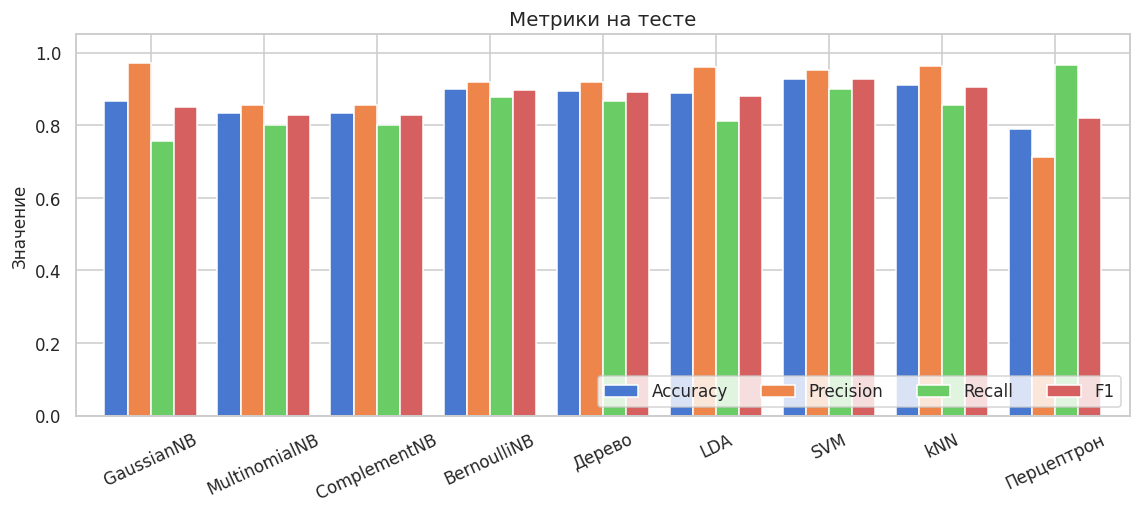

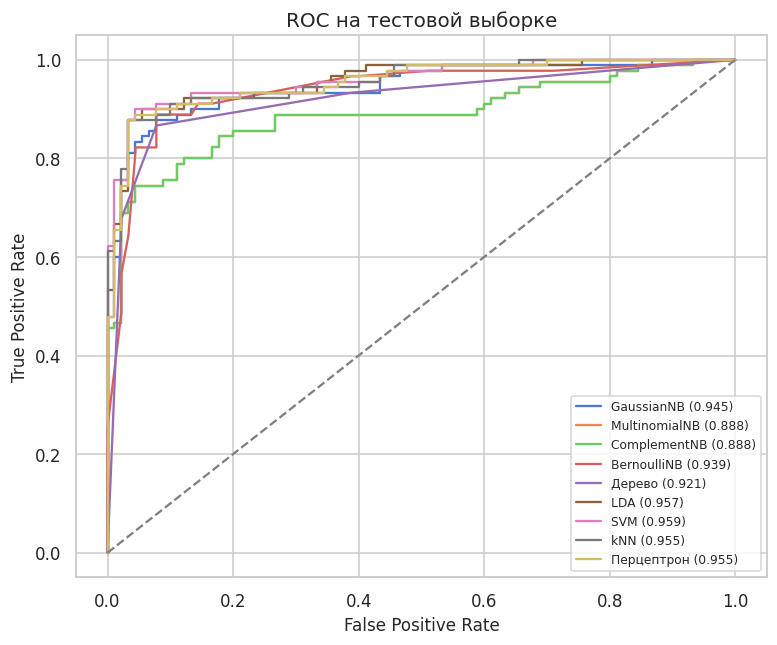

Максимум F1: SVM = 0.926
Максимум AUC: SVM = 0.959


In [7]:
compare = metrics_cls.copy()
compare.loc["Перцептрон"] = pd.Series(nn_row).drop(labels=["Модель"])
tuned_f1 = metrics_tuned["F1"].copy()
tuned_f1.loc["Перцептрон"] = nn_tuned["F1"]
compare["F1 при подобранном пороге"] = tuned_f1
compare = compare.round(3)
print(compare.to_string())

fig, ax = plt.subplots(figsize=(10.5, 4.8))
compare[["Accuracy", "Precision", "Recall", "F1"]].plot(kind="bar", ax=ax, width=0.82)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Значение")
ax.set_xlabel("")
ax.set_title("Метрики на тесте")
ax.legend(loc="lower right", ncol=4)
ax.tick_params(axis="x", rotation=25)
plt.show()

fig, ax = plt.subplots(figsize=(7.2, 6.0))
for name, scores in score_bank.items():
    fpr, tpr, _ = roc_curve(y_test, scores)
    ax.plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_test, scores):.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC на тестовой выборке")
ax.legend(fontsize=8, loc="lower right")
plt.show()

winner = compare["F1"].idxmax()
print(f"Максимум F1: {winner} = {compare.loc[winner, 'F1']:.3f}")
print(f"Максимум AUC: {compare['AUC-ROC'].idxmax()} = {compare['AUC-ROC'].max():.3f}")

### Пояснение к сравнению

По F1 при пороге 0,5 лидирует **SVM: 0,926**. Его же accuracy **0,928** и AUC **0,959** — максимумы таблицы. kNN рядом: accuracy **0,911**, F1 **0,906**, AUC **0,955**. Перцептрон при 0,5 имеет accuracy **0,789** и F1 **0,821**, но AUC **0,955**: ошибка в пороге, а не в порядке зёрен. После порога валидации его F1 становится **0,909** и всё ещё не обгоняет SVM.

MultinomialNB и ComplementNB при alpha = 1000 дают F1 **0,828**. Это выше плоского участка малых alpha, но всё ещё ниже остальных методов: пиксельная площадь для них — не частота. ROC сильных моделей отходит от диагонали, но не прижимается к углу: часть зёрен двух сортов действительно похожа.

### 8) Заключение

В файле **900** зёрен, пропусков и повторов нет, сорта поровну. Обучение — 720 строк, тест — 180, seed равен 42. Совпавших по признакам строк между частями **0**. Бесни крупнее: средняя площадь **112195** против **63413** у Кечимен, но распределения пересекаются.

На тесте лучший метод — **линейный SVM**, C = 1, без весов классов: accuracy **0,928**, precision **0,953**, recall **0,900**, F1 **0,926**, AUC **0,959**. kNN при k = 41 даёт F1 **0,906**. Дерево глубины 2 — F1 **0,891**. LDA — AUC **0,957** и F1 **0,880**. Перцептрон 32–16–8, sigmoid, 15 эпох, батч 32 при пороге 0,5 даёт accuracy **0,789** и F1 **0,821**; порог 0,525 с валидации поднимает accuracy до **0,911** и F1 до **0,909**. AUC перцептрона **0,955**, то есть разделение по рангу близко к SVM.

Для этих признаков достаточно линейного SVM. Перцептрон выходит на тот же уровень только после сдвига порога и не поднимает F1 выше зазора. Accuracy не равна 1, потому что два сорта перекрываются по размеру, а не потому что одни и те же зёрна попали в обе выборки.